# a sanity on the values of dbdt

In [2]:
from anemone.experiment import Loop, Receiver, Forward
import matplotlib.pyplot as plt
import numpy as np
import torch
from anemone import constants as c


In [ ]:
# a for a circle
a = np.sqrt(40*40/np.pi)
#a for a square
# a=50

In [20]:
from anemone.transforms import precalcHankel1, BaseHankel, BaseFourier, CubicSpline
from anemone.physics import refl_transverse_electric as rte, freespace_u0 as u0, mu0
from anemone.experiment import *
from anemone import constants as c
import torch



class Forward:
    def __init__(self, source, receiver, times, a):
        self.source = source
        self.receiver = receiver
        self.times = torch.tensor(times)
        self.rmin = self.source.min_horizontal_distance(self.receiver)
        self.rmax = self.source.max_horizontal_distance(self.receiver)
        self.dz = torch.tensor(self.receiver.z+self.source.z[0])

    def forward(self):
        def frq_integrand(f):
            omega = c.twopi*f[None,:,None]
            def wvlngth_integrand(wave_length):
                """ Hz from horizontal electric dipole.
                see equation """
                lmb = wave_length[None, None, :]
                tmp_u0 = u0(omega, lmb)
                intg = torch.squeeze((torch.exp(-tmp_u0*self.dz)*rte(self.sigma, self.thick, omega, lmb))*lmb**2 / tmp_u0)
                return intg/c.fourpi
            hkl1 = Hankel(wvlngth_integrand, 1, smp_per_decade=20, range=(self.rmin, self.rmax))
            return integrate_around_loop(self.source, self.receiver, hkl1)
        ift=invFourier(frq_integrand, smp_per_decade=20)
        cbft = CubicSpline(*ift.range(self.times[0], self.times[-1]), transform=torch.log10)
        return cbft(self.times)

    def __call__(self, sigma, thickness):
        self.sigma = torch.tensor(sigma,     dtype=torch.complex128)[...,None,None]
        self.thick = torch.tensor(thickness, dtype=torch.complex128)[...,None,None]
        return self.forward()
    

    

C:\Users\admin\AppData\Local\Temp\ipykernel_20852\582219562.py:46: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.sigma = torch.tensor(sigma,     dtype=torch.complex128)[...,None,None]
C:\Users\admin\AppData\Local\Temp\ipykernel_20852\582219562.py:47: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.thick = torch.tensor(thickness, dtype=torch.complex128)[...,None,None]
c:\Users\admin\Documents\Repositories\anemone\venv\Lib\site-packages\anemone\transforms\transforms.py:236: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  rout = torch.

torch.Size([20])


In [15]:
ainv_dbdt=np.array([2.749861e-04, 1.753167e-04, 1.011688e-04, 6.031561e-05,
       3.650625e-05, 2.059544e-05, 1.194428e-05, 7.079678e-06,
       3.957627e-06, 2.293402e-06, 1.403765e-06, 8.236817e-07,
       4.389777e-07, 2.446409e-07, 1.422868e-07, 7.752075e-08,
       4.302391e-08, 2.479088e-08, 1.362022e-08, 7.621867e-09])

times = np.array([9.350e-06, 1.145e-05, 1.458e-05, 1.822e-05, 2.255e-05, 2.867e-05,
       3.595e-05, 4.460e-05, 5.660e-05, 7.070e-05, 8.630e-05, 1.071e-04,
       1.381e-04, 1.748e-04, 2.174e-04, 2.775e-04, 3.515e-04, 4.385e-04,
       5.575e-04, 7.035e-04])

In [5]:
lp = Loop.circle(a, n=100)
#lp = Loop.square(40, z=0.02)
rx=Receiver(z=0.02)

rho = 40
sigma = 1/torch.tensor([rho,rho, rho, rho, rho])
thick = torch.tensor([1, 2, 20, 40])

# fwr = Forward(lp, rx, np.logspace(-9, -1, 51))
fwr = Forward(lp, rx, times, a)
from time import perf_counter as timer
bt = timer()
dbdt = fwr(sigma, thick)
print(dbdt.shape)

C:\Users\admin\AppData\Local\Temp\ipykernel_20852\2939111005.py:46: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.sigma = torch.tensor(sigma,     dtype=torch.complex128)[...,None,None]
C:\Users\admin\AppData\Local\Temp\ipykernel_20852\2939111005.py:47: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.thick = torch.tensor(thickness, dtype=torch.complex128)[...,None,None]


torch.Size([20])


c:\Users\admin\Documents\Repositories\anemone\venv\Lib\site-packages\anemone\transforms\transforms.py:236: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  rout = torch.tensor(10**(i_offsets/self.smp_per_decade), dtype=torch.complex128)
c:\Users\admin\Documents\Repositories\anemone\venv\Lib\site-packages\anemone\transforms\transforms.py:297: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  tout = torch.tensor(10**(i_offsets/self.smp_per_decade))


In [6]:
a = np.sqrt(40*40/np.pi)
radii  = np.geomspace(1, a, 5)
ratios = np.zeros_like(radii)
ratios_std = np.zeros_like(radii)
rho = 40
from scipy.special import erf


for ir,a in enumerate(radii):
    lp = Loop.circle(a, n=100)
    fwr = Forward(lp, rx, times, a)
    dbdt = fwr(sigma, thick)


    sgm = (1./rho)
    theta = np.sqrt(0.25*mu0*sgm / fwr.times.numpy())
    dhdt = 1./(mu0*sgm*a**3)*(3*erf(theta*a)-2*theta*a*(3+2*theta**2*a**2)*np.exp(-theta**2*a**2)/np.sqrt(np.pi))

    ratio = (dhdt.real/dbdt.real).cpu().numpy()
    ratios[ir] = ratio.mean()
    ratios_std[ir] = np.var(ratio)
ratios_std = np.sqrt(ratios_std)

C:\Users\admin\AppData\Local\Temp\ipykernel_20852\2939111005.py:46: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.sigma = torch.tensor(sigma,     dtype=torch.complex128)[...,None,None]
C:\Users\admin\AppData\Local\Temp\ipykernel_20852\2939111005.py:47: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.thick = torch.tensor(thickness, dtype=torch.complex128)[...,None,None]


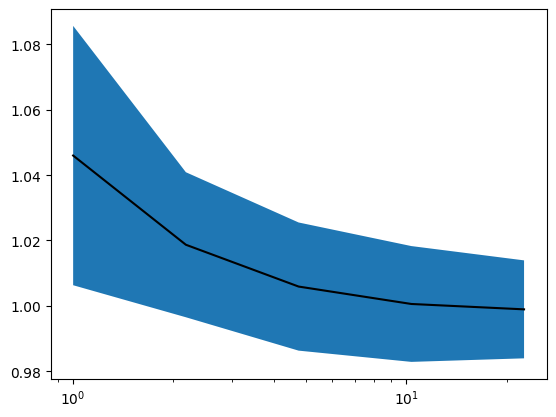

In [7]:
plt.figure()
plt.fill_between(radii, ratios-ratios_std, ratios+ratios_std)
plt.plot(radii, ratios, 'k-')
# plt.plot(radii, radii)
plt.xscale('log')
# plt.yscale('log')

In [8]:
20*np.sqrt(np.pi)

35.449077018110316

In [9]:
dhdt_lt = (1./40)**(3/2) * mu0**(3/2) * a**2 * fwr.times.numpy()**(-5/2) / (20*np.sqrt(np.pi))

In [10]:
1/8

0.125

In [11]:
from scipy.special import erf


sgm = (1./rho)
theta = np.sqrt(0.25*mu0*sgm / fwr.times.numpy())
dhdt = 1./(mu0*sgm*a**3)*(3*erf(theta*a)-2*theta*a*(3+2*theta**2*a**2)*np.exp(-theta**2*a**2)/np.sqrt(np.pi))

In [12]:
dhdt/np.abs(dbdt.real)

tensor([0.9435, 1.0065, 1.0118, 1.0103, 1.0120, 1.0058, 1.0009, 1.0084, 1.0017,
        1.0028, 1.0051, 1.0011, 1.0025, 1.0014, 1.0013, 1.0026, 1.0020, 1.0027,
        1.0030, 1.0035], dtype=torch.float64)

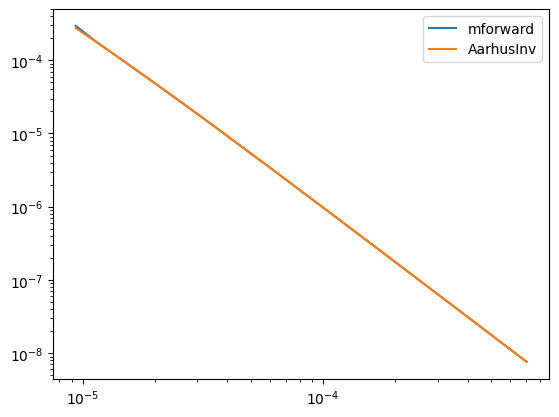

In [13]:
fig,ax = plt.subplots()
ax.loglog(fwr.times.numpy(), mu0*dbdt.real, label='mforward')
ax.loglog(times,      ainv_dbdt, label='AarhusInv')
# ax.loglog(fwr.times.numpy(),       dhdt*mu0, '--', label='analytic')
# ax.loglog(fwr.times.numpy(),       dhdt_lt*mu0, '--', label='analytic1')
ax.legend()